
# Deux modèles, deux questions

Les clients actifs et suspendus n'ont pas la même problématique.

| Population | Nombre | Situation | Question |
|---|---|---|---|
| Actifs (`A`) | 25 466 | utilisent leur ligne | va-t-il partir ? |
| Suspendus (`S`) | 8 534 | ligne coupée | va-t-il revenir ? |

Devenir des suspendus le mois suivant :

| Devient | Nombre | % |
|---|---|---|
| Départ définitif | 4 955 | 58,1 % |
| Reste suspendu | 2 118 | 24,8 % |
| Revient actif | 1 461 | 17,1 % |

Entrée : `data/final/modele_comportement.csv` et `all_tables.csv` (pour
`STATUT`). Une seule observation par client : pas de validation temporelle,
les scores restent optimistes.



## 1. Chargement


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.inspection import permutation_importance

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
FINAL = ROOT / 'data' / 'final'

donnees = pd.read_csv(FINAL / 'modele_comportement.csv',
                      keep_default_na=False, na_values=[''], low_memory=False)

statut = pd.read_csv(FINAL / 'all_tables.csv',
                     keep_default_na=False, na_values=[''], low_memory=False)['STATUT']

donnees['STATUT'] = statut.to_numpy()

COLONNES = [c for c in donnees.columns if c not in ('churn', 'STATUT')]

print('données :', donnees.shape)
print('répartition :')
print(donnees['STATUT'].value_counts().to_string())


données : (34000, 10)
répartition :
STATUT
A    25466
S     8534



## 2. Les deux labels

| Modèle | Population | Label | Signification de 1 |
|---|---|---|---|
| Actifs | 25 466 | `churn` | il part |
| Suspendus | 8 534 | `revenir` | il redevient actif |

Pour les suspendus le label est l'inverse de `churn` : revenir signifie
`churn = 0`.


In [2]:

actifs = donnees[donnees['STATUT'] == 'A'].reset_index(drop=True)
y_actifs = actifs['churn']

suspendus = donnees[donnees['STATUT'] == 'S'].reset_index(drop=True)
y_suspendus = (suspendus['churn'] == 0).astype(int)

print('population active')
print(f'  clients        : {len(actifs):,}')
print(f'  partent (1)    : {int(y_actifs.sum()):,}  ({y_actifs.mean()*100:.1f} %)')
print()
print('population suspendue')
print(f'  clients        : {len(suspendus):,}')
print(f'  reviennent (1) : {int(y_suspendus.sum()):,}  ({y_suspendus.mean()*100:.1f} %)')


population active
  clients        : 25,466
  partent (1)    : 2,487  (9.8 %)

population suspendue
  clients        : 8,534
  reviennent (1) : 1,461  (17.1 %)



## 3. Entraînement

Découpage 80 / 20, stratifié : la proportion de positifs est conservée des
deux côtés. Les 20 % de test ne sont jamais vus à l'entraînement.


In [3]:

def entrainer_et_evaluer(X, y, nom, graine=42):
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=0.20, random_state=graine, stratify=y)

    modele = HistGradientBoostingClassifier(
        max_iter=250, learning_rate=0.06, random_state=graine)
    modele.fit(X_tr, y_tr)

    proba = modele.predict_proba(X_te)[:, 1]
    auc = roc_auc_score(y_te, proba)

    print(f'{nom:34s} entraînement {len(X_tr):>6,} | test {len(X_te):>5,} | AUC {auc:.4f}')
    return {'modele': modele, 'X_te': X_te, 'y_te': y_te,
            'proba': proba, 'auc': auc}

resultat_actifs = entrainer_et_evaluer(actifs[COLONNES], y_actifs, 'Actifs (partir)')
resultat_suspendus = entrainer_et_evaluer(suspendus[COLONNES], y_suspendus, 'Suspendus (revenir)')


Actifs (partir)                    entraînement 20,372 | test 5,094 | AUC 0.7885


Suspendus (revenir)                entraînement  6,827 | test 1,707 | AUC 0.6875



## 4. Comparaison des scores

| Modèle | AUC | Hasard |
|---|---|---|
| Actifs | environ 0,79 | 0,50 |
| Suspendus | environ 0,69 | 0,50 |

Prédire un retour (17 % de cas) est plus difficile que prédire un départ chez
des clients actifs. Le modèle des suspendus reste au-dessus du hasard et
permet de trier.


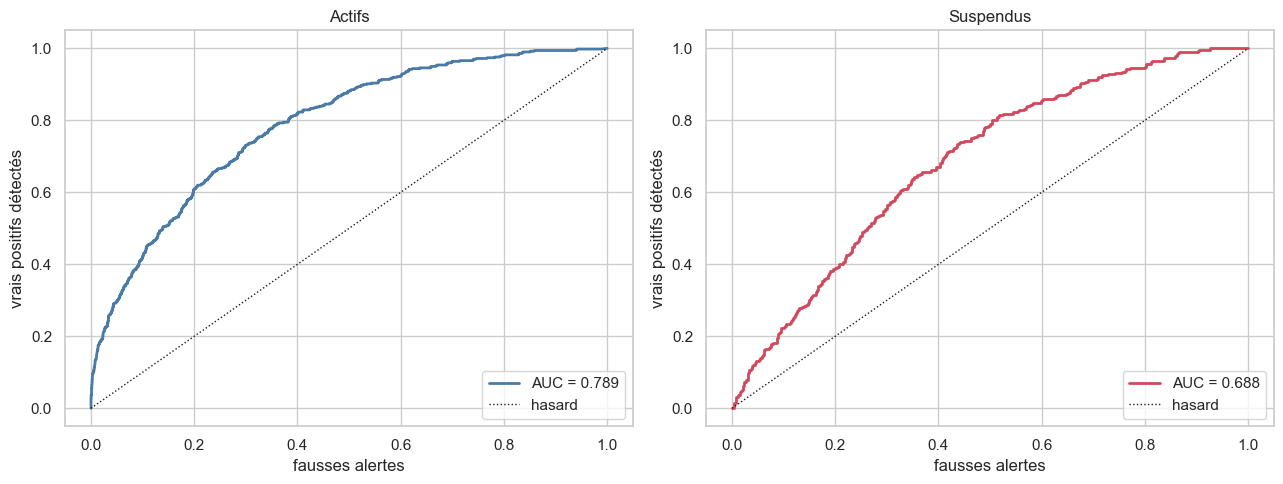

In [4]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, res, nom, couleur in [
        (axes[0], resultat_actifs, 'Actifs', '#4a7ba7'),
        (axes[1], resultat_suspendus, 'Suspendus', '#d1495b')]:
    fpr, tpr, _ = roc_curve(res['y_te'], res['proba'])
    ax.plot(fpr, tpr, color=couleur, linewidth=2, label=f'AUC = {res["auc"]:.3f}')
    ax.plot([0, 1], [0, 1], 'k:', linewidth=1, label='hasard')
    ax.set_xlabel('fausses alertes')
    ax.set_ylabel('vrais positifs détectés')
    ax.set_title(nom)
    ax.legend(loc='lower right')

plt.tight_layout()
plt.show()


In [5]:

comparaison = pd.DataFrame([
    {'modèle': 'actifs', 'population': len(actifs), 'label': 'partir',
     'taux_positifs': f'{y_actifs.mean()*100:.1f} %',
     'AUC': f'{resultat_actifs["auc"]:.4f}'},
    {'modèle': 'suspendus', 'population': len(suspendus), 'label': 'revenir',
     'taux_positifs': f'{y_suspendus.mean()*100:.1f} %',
     'AUC': f'{resultat_suspendus["auc"]:.4f}'},
])
print(comparaison.to_string(index=False))


   modèle  population   label taux_positifs    AUC
   actifs       25466  partir         9.8 % 0.7885
suspendus        8534 revenir        17.1 % 0.6875



## 5. Gain sur une liste d'appels

On trie par score décroissant et on compte les vrais positifs dans les
premiers clients, comparé à un tirage au hasard.


In [6]:

def gain_par_taille(res, taille, nom):
    ordre = np.argsort(-np.asarray(res['proba'], dtype=float))[:taille]
    y = np.asarray(res['y_te'])[ordre]
    captures = int(y.sum())
    taux = y.mean() * 100
    base = np.asarray(res['y_te']).mean() * 100
    print(f'{nom:12s} top {taille:>4,} : {captures:>4,} positifs '
          f'({taux:>4.0f} %)  |  hasard {base:.1f} %  |  gain x{taux/base:.1f}')

print('actifs')
gain_par_taille(resultat_actifs, 300, 'actifs')
gain_par_taille(resultat_actifs, 1000, 'actifs')
print()
print('suspendus')
gain_par_taille(resultat_suspendus, 150, 'suspendus')
gain_par_taille(resultat_suspendus, 500, 'suspendus')


actifs
actifs       top  300 :  129 positifs (  43 %)  |  hasard 9.8 %  |  gain x4.4
actifs       top 1,000 :  262 positifs (  26 %)  |  hasard 9.8 %  |  gain x2.7

suspendus
suspendus    top  150 :   49 positifs (  33 %)  |  hasard 17.1 %  |  gain x1.9
suspendus    top  500 :  143 positifs (  29 %)  |  hasard 17.1 %  |  gain x1.7



## 6. Variables utilisées par chaque modèle

L'importance par permutation montre sur quoi chaque modèle s'appuie.


In [7]:

importances = {}
for res, nom in [(resultat_actifs, 'actifs'), (resultat_suspendus, 'suspendus')]:
    imp = permutation_importance(
        res['modele'], res['X_te'], res['y_te'],
        n_repeats=8, random_state=42, scoring='roc_auc', n_jobs=-1)
    importances[nom] = imp.importances_mean

tableau_imp = pd.DataFrame(importances, index=COLONNES).sort_values('actifs', ascending=False)
print(tableau_imp.round(4).to_string())


                actifs  suspendus
MNT_RECH        0.0767     0.0623
HANDSET         0.0611    -0.0002
ANC_M           0.0339     0.0329
APPEL_TOTAL     0.0290     0.0056
SMS_TOTAL       0.0156     0.0525
VOLUME_SESSION  0.0063     0.0015
MNT_FORFAIT     0.0028     0.0062
OFFRE           0.0023     0.0029



### Lecture

| Variable | Actifs | Suspendus | Lecture |
|---|---|---|---|
| `MNT_RECH` | fort | fort | compte pour les deux |
| `HANDSET` | fort | quasi nul | un suspendu n'utilise plus son téléphone |
| `SMS_TOTAL` | moyen | plus fort | les SMS continuent d'arriver ligne coupée |
| `ANC_M` | moyen | moyen | l'ancienneté compte partout |

La hiérarchie change selon la question posée : ce ne sont pas deux copies du
même modèle.



## 7. Application sur les données du mois

```
Nouvelles données
       |
  séparer par STATUT
   /            \
actifs        suspendus
   |              |
modèle 1       modèle 2
(partir)       (revenir)
   |              |
liste 1        liste 2
relances       réactivations
```

Les scores ne s'additionnent pas : un actif à 90 % a 90 % de chances de
partir, un suspendu à 30 % a 30 % de chances de revenir.


In [8]:

def scorer_nouveaux(nouveaux, modele_actifs, modele_suspendus):
    resultat = pd.DataFrame(index=nouveaux.index)
    resultat['STATUT'] = nouveaux['STATUT']

    masque_a = (nouveaux['STATUT'] == 'A').to_numpy()
    if masque_a.any():
        resultat.loc[masque_a, 'risque_partir'] = modele_actifs.predict_proba(
            nouveaux.loc[masque_a, COLONNES])[:, 1]

    masque_s = (nouveaux['STATUT'] == 'S').to_numpy()
    if masque_s.any():
        resultat.loc[masque_s, 'risque_revenir'] = modele_suspendus.predict_proba(
            nouveaux.loc[masque_s, COLONNES])[:, 1]

    return resultat

nouveaux = donnees.sample(2000, random_state=7).copy()
scores = scorer_nouveaux(nouveaux, resultat_actifs['modele'], resultat_suspendus['modele'])
scores['churn_reel'] = nouveaux['churn']

print('actifs scorés    :', int(scores['risque_partir'].notna().sum()))
print('suspendus scorés :', int(scores['risque_revenir'].notna().sum()))
print()
print(scores.head(8).to_string())


actifs scorés    : 1489
suspendus scorés : 511

      STATUT  risque_partir  risque_revenir  churn_reel
16506      A       0.153149             NaN           0
33788      S            NaN        0.039556           1
15854      A       0.068673             NaN           0
24826      S            NaN        0.140531           1
21063      S            NaN        0.160243           0
18057      A       0.026722             NaN           0
25831      S            NaN        0.160827           1
7656       A       0.104381             NaN           0


In [9]:

print('LISTE 1 — RELANCES (clients actifs)')
liste1 = scores[scores['STATUT'] == 'A'].nlargest(10, 'risque_partir')
for i, (_, ligne) in enumerate(liste1.iterrows(), 1):
    reel = 'part' if ligne['churn_reel'] == 1 else 'reste'
    print(f'  {i:>2}. risque {ligne["risque_partir"]*100:>5.1f} %   ({reel})')

print()
print('LISTE 2 — RÉACTIVATIONS (clients suspendus)')
liste2 = scores[scores['STATUT'] == 'S'].nlargest(10, 'risque_revenir')
for i, (_, ligne) in enumerate(liste2.iterrows(), 1):
    reel = 'revient' if ligne['churn_reel'] == 0 else 'part'
    print(f'  {i:>2}. chance {ligne["risque_revenir"]*100:>5.1f} %   ({reel})')


LISTE 1 — RELANCES (clients actifs)
   1. risque  80.0 %   (part)
   2. risque  77.7 %   (part)
   3. risque  77.3 %   (part)
   4. risque  70.9 %   (part)
   5. risque  68.7 %   (part)
   6. risque  64.1 %   (reste)
   7. risque  62.6 %   (part)
   8. risque  61.3 %   (part)
   9. risque  60.7 %   (part)
  10. risque  59.6 %   (reste)

LISTE 2 — RÉACTIVATIONS (clients suspendus)
   1. chance  79.3 %   (revient)
   2. chance  75.0 %   (revient)
   3. chance  74.6 %   (revient)
   4. chance  73.0 %   (revient)
   5. chance  72.0 %   (revient)
   6. chance  71.0 %   (revient)
   7. chance  70.8 %   (revient)
   8. chance  70.1 %   (revient)
   9. chance  69.5 %   (revient)
  10. chance  68.6 %   (revient)



## 8. Tableau de bord

Pour le reporting, un comptage sur `STATUT` suffit.


In [10]:

print('TABLEAU DE BORD')
print(f'Clients total : {len(donnees):,}')
print(f'Risque global : {donnees["churn"].mean()*100:.1f} %')
print()
for s, nom in [('A', 'Actifs'), ('S', 'Suspendus')]:
    sub = donnees[donnees['STATUT'] == s]
    print(f'  {nom:10s} {len(sub):>6,} clients  ->  {int(sub["churn"].sum()):>5,} à risque '
          f'({sub["churn"].mean()*100:>4.1f} %)')
print()
print('Actions : 1 000 relances + 500 réactivations')


TABLEAU DE BORD
Clients total : 34,000
Risque global : 28.1 %

  Actifs     25,466 clients  ->  2,487 à risque ( 9.8 %)
  Suspendus   8,534 clients  ->  7,073 à risque (82.9 %)

Actions : 1 000 relances + 500 réactivations



## 9. Limites

1. **Pas de validation temporelle.** Une seule observation par client, un seul
   label. Les scores mesurent la capacité à trier ces clients-ci.
2. **Le modèle des suspendus est faible** (environ 0,69). Il sert à trier
   grossièrement.
3. **Fort déséquilibre chez les suspendus.** 17,1 % de positifs : un modèle
   répondant « personne ne revient » aurait raison 82,9 % du temps. D'où le
   choix de l'AUC plutôt que de l'accuracy.
4. **`OFFRE` n'apporte presque rien** malgré ses 65 modalités.

## 10. Conclusion

| Outil | Répond à | AUC | Usage |
|---|---|---|---|
| Statistique `STATUT` | combien sont à risque ? | — | reporting |
| Modèle actifs | qui appeler pour retenir ? | 0,79 | relances |
| Modèle suspendus | qui appeler pour réactiver ? | 0,69 | réactivations |

Un modèle incluant `STATUT` atteint 0,92 d'AUC, mais il ne fait que constater
les départs déjà actés. Les deux modèles ci-dessus portent sur les populations
où une action reste possible.

Processus mensuel : extraire, nettoyer (notebook 03), séparer actifs et
suspendus, scorer, lancer les deux campagnes, reporter.

Tant que la validation temporelle n'est pas faite, les chiffres restent des
estimations optimistes.
